# Book Recommender with a Medallion Data Lake
**Data Mining Lab Assignment** – Book-Crossing dataset (Users, Books, Book-Ratings)

Pipeline: **Raw CSV → Bronze (Parquet) → Silver (cleaned) → Gold (model-ready) → Item-based collaborative filtering**

| Layer | Folder | Contents |
|---|---|---|
| Bronze | `bronze/` | Untouched copy of the source + `ingestion_timestamp` |
| Silver | `silver/` | Cleaned, validated, filtered tables |
| Gold | `gold/` | Sparse rating matrix, book lookup, user/book aggregates |

## Step 1 – Set up the data lake and build the Bronze layer

In [8]:
import os, re, html, string, urllib.request, zipfile
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# the three lake folders
for layer in ["bronze", "silver", "gold"]:
    os.makedirs(layer, exist_ok=True)
print("Folders:", [d for d in ["bronze", "silver", "gold"] if os.path.isdir(d)])

Folders: ['bronze', 'silver', 'gold']


In [9]:
import shutil

RAW = "raw"
os.makedirs(RAW, exist_ok=True)

for csv_file in ["BX-Users.csv", "BX-Books.csv", "BX-Book-Ratings.csv"]:
    src_path = csv_file
    dst_path = os.path.join(RAW, csv_file)
    if os.path.exists(src_path):
        shutil.move(src_path, dst_path)
        print(f"Moved {src_path} to {dst_path}")
    elif os.path.exists(dst_path):
        print(f"{dst_path} already exists in raw/")
    else:
        print(f"Warning: {csv_file} not found in current directory or raw/")

for name in sorted(os.listdir(RAW)):
    print(name, f"{os.path.getsize(os.path.join(RAW, name)) / 1e6:.1f} MB")

raw/BX-Users.csv already exists in raw/
raw/BX-Books.csv already exists in raw/
raw/BX-Book-Ratings.csv already exists in raw/
BX-Book-Ratings.csv 30.7 MB
BX-Books.csv 77.8 MB
BX-Users.csv 12.3 MB


The raw files are **semicolon-separated** and **not UTF-8** (they are Latin-1 / ISO-8859-1), so we read them with `sep=";"` and `encoding="latin-1"`.
`on_bad_lines="skip"` is a safety net for the few malformed lines in the source. No other transformation is applied.

In [10]:
read_kw = dict(sep=";", encoding="latin-1", on_bad_lines="skip", low_memory=False)

users_raw   = pd.read_csv(f"{RAW}/BX-Users.csv", **read_kw)
books_raw   = pd.read_csv(f"{RAW}/BX-Books.csv", **read_kw)
ratings_raw = pd.read_csv(f"{RAW}/BX-Book-Ratings.csv", **read_kw)

# Bronze = exact copy of the source + ingestion timestamp. NOTHING is cleaned here.
ts = pd.Timestamp.now(tz="UTC")
for name, df in [("users", users_raw), ("books", books_raw), ("ratings", ratings_raw)]:
    df["ingestion_timestamp"] = ts
    df.to_parquet(f"bronze/{name}.parquet", index=False)
    print(f"bronze/{name}.parquet  ->  {df.shape[0]:,} rows x {df.shape[1]} cols")

bronze/users.parquet  ->  278,858 rows x 4 cols
bronze/books.parquet  ->  271,360 rows x 9 cols
bronze/ratings.parquet  ->  1,149,780 rows x 4 cols


## Step 2 – Explore the Bronze data (EDA)

In [11]:
# Read the Bronze tables back (this is what Silver will consume)
users_b   = pd.read_parquet("bronze/users.parquet")
books_b   = pd.read_parquet("bronze/books.parquet")
ratings_b = pd.read_parquet("bronze/ratings.parquet")

for name, df in [("users", users_b), ("books", books_b), ("ratings", ratings_b)]:
    print(f"===== {name}: shape = {df.shape}")
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
                        "missing_%": (df.isna().mean() * 100).round(2)}))
    print()

===== users: shape = (278858, 4)
                                   dtype  missing  missing_%
User-ID                            int64        0       0.00
Location                          object        0       0.00
Age                              float64   110762      39.72
ingestion_timestamp  datetime64[us, UTC]        0       0.00

===== books: shape = (271360, 9)
                                   dtype  missing  missing_%
ISBN                              object        0        0.0
Book-Title                        object        0        0.0
Book-Author                       object        2        0.0
Year-Of-Publication               object        0        0.0
Publisher                         object        2        0.0
Image-URL-S                       object        0        0.0
Image-URL-M                       object        0        0.0
Image-URL-L                       object        3        0.0
ingestion_timestamp  datetime64[us, UTC]        0        0.0

===== ratings: sh

**2.1 Shape, data types, missing values.** Users 278,858×3, Books 271,360×8, Ratings 1,149,780×3 (all +1 for `ingestion_timestamp`); only `Age` has heavy missingness (110,762 = 39.7%), while `Book-Author`/`Publisher` miss 2 and `Image-URL-L` 3 values, and `Year-Of-Publication` is stored as text → in Silver I convert year to numeric, fill ages with the median, and drop the image-URL columns.

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Ratings equal to 0: 716,109 of 1,149,780 (62.3%)


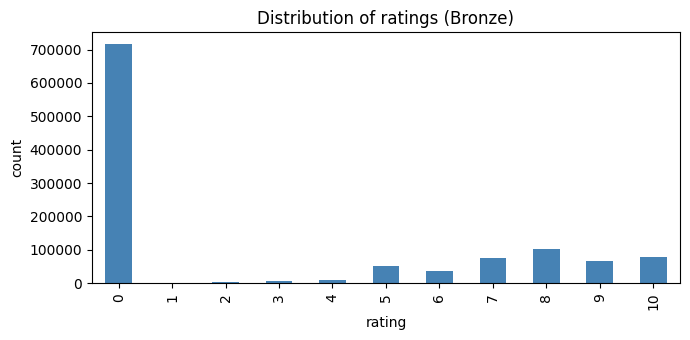

In [12]:
print(ratings_b["Book-Rating"].value_counts().sort_index())
n_zero = (ratings_b["Book-Rating"] == 0).sum()
print(f"\nRatings equal to 0: {n_zero:,} of {len(ratings_b):,} ({n_zero / len(ratings_b):.1%})")

fig, ax = plt.subplots(figsize=(7, 3.5))
ratings_b["Book-Rating"].value_counts().sort_index().plot.bar(ax=ax, color="steelblue")
ax.set_title("Distribution of ratings (Bronze)"); ax.set_xlabel("rating"); ax.set_ylabel("count")
plt.tight_layout(); plt.show()

**2.2 Rating distribution.** 716,109 of 1,149,780 ratings (62.3%) are 0, i.e. *no explicit rating*; the explicit 1–10 ratings are skewed high (mode 8, mean ≈ 7.6) → in Silver I drop all 0s, leaving 433,671 explicit ratings.

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Age < 5   : 882
Age > 100 : 366
Age missing: 110,762 (39.7%)

Year non-numeric : 3
Year == 0        : 4,618
Year > 2026   : 11
Year 1 - 1799    : 2
count    266739.000000
mean       1993.689772
std           8.325811
min        1376.000000
25%        1989.000000
50%        1996.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64


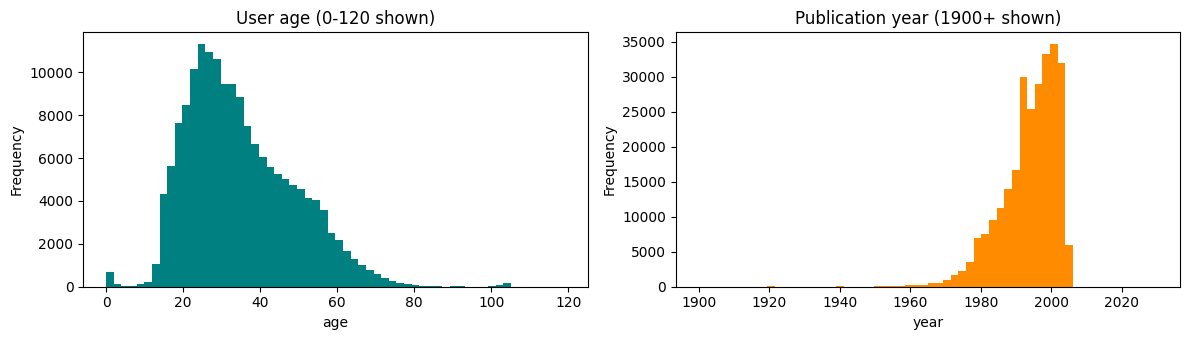

In [13]:
age = users_b["Age"]
print(age.describe())
print(f"\nAge < 5   : {(age < 5).sum():,}")
print(f"Age > 100 : {(age > 100).sum():,}")
print(f"Age missing: {age.isna().sum():,} ({age.isna().mean():.1%})")

yr = pd.to_numeric(books_b["Year-Of-Publication"], errors="coerce")
this_year = datetime.now().year
print(f"\nYear non-numeric : {(yr.isna() & books_b['Year-Of-Publication'].notna()).sum():,}")
print(f"Year == 0        : {(yr == 0).sum():,}")
print(f"Year > {this_year}   : {(yr > this_year).sum():,}")
print(f"Year 1 - 1799    : {((yr > 0) & (yr < 1800)).sum():,}")
print(yr[yr > 0].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
age[(age >= 0) & (age <= 120)].plot.hist(bins=60, ax=axes[0], color="teal")
axes[0].set_title("User age (0-120 shown)"); axes[0].set_xlabel("age")
yr[(yr >= 1900) & (yr <= this_year + 10)].plot.hist(bins=60, ax=axes[1], color="darkorange")
axes[1].set_title("Publication year (1900+ shown)"); axes[1].set_xlabel("year")
plt.tight_layout(); plt.show()

**2.3 Age and publication year.** Ages include 882 values < 5 (many are 0), 366 values > 100 (max 244) and 39.7% nulls; years include 4,618 zeros, 11 future years (up to 2050) and 3 non-numeric values → in Silver I null the 1,248 impossible ages and fill all nulls with the median (32), and null every 0 / future / non-numeric year (4,632 in total; two ancient years such as 1376 are left because the brief only asks for 0 and future years).

Ratings per user:
 count    105283.00
mean         10.92
std          90.56
min           1.00
25%           1.00
50%           1.00
75%           4.00
max       13602.00
dtype: float64 

Ratings per book:
 count    340556.00
mean          3.38
std          12.44
min           1.00
25%           1.00
50%           1.00
75%           2.00
max        2502.00
dtype: float64 

>=  1 ratings: 100.0% of users | 100.0% of books
>=  2 ratings:  43.8% of users |  42.1% of books
>=  5 ratings:  21.7% of users |  12.9% of books
>= 10 ratings:  12.4% of users |   5.4% of books
>= 20 ratings:   7.0% of users |   2.2% of books


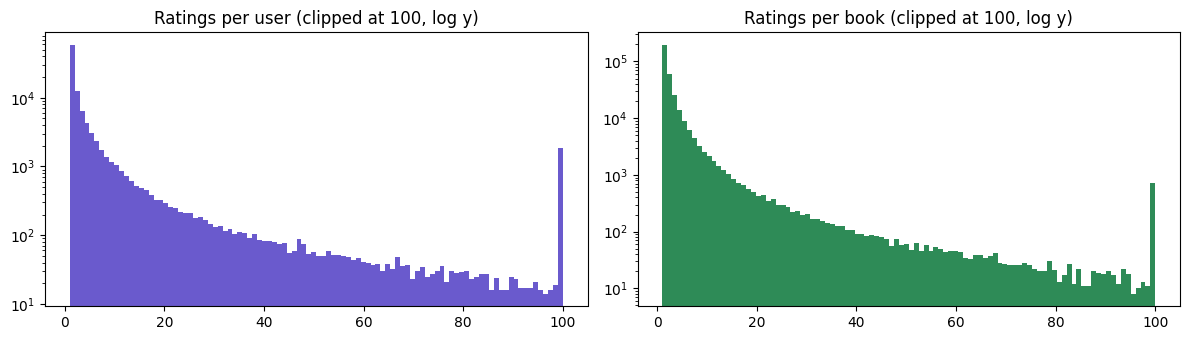

In [14]:
per_user = ratings_b.groupby("User-ID").size()
per_book = ratings_b.groupby("ISBN").size()
print("Ratings per user:\n", per_user.describe().round(2), "\n")
print("Ratings per book:\n", per_book.describe().round(2), "\n")
for t in [1, 2, 5, 10, 20]:
    print(f">= {t:>2} ratings: {(per_user >= t).mean():6.1%} of users | {(per_book >= t).mean():6.1%} of books")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(per_user.clip(upper=100), bins=100, color="slateblue"); axes[0].set_yscale("log")
axes[0].set_title("Ratings per user (clipped at 100, log y)")
axes[1].hist(per_book.clip(upper=100), bins=100, color="seagreen"); axes[1].set_yscale("log")
axes[1].set_title("Ratings per book (clipped at 100, log y)")
plt.tight_layout(); plt.show()

**2.4 Ratings per user / per book.** The median user and the median book have just 1 rating (75% of users have ≤ 4), while one user has 13,602 ratings; only 12.4% of users and 5.4% of books have ≥ 10 ratings → in Silver I keep only users and books with a minimum number of ratings (threshold chosen in step 3.8).

In [15]:
def sparsity(df, label):
    n_u, n_b, n_r = df["User-ID"].nunique(), df["ISBN"].nunique(), len(df)
    cells_ = n_u * n_b
    print(f"{label}: {n_u:,} users x {n_b:,} books = {cells_:,.0f} possible pairs, "
          f"{n_r:,} ratings -> density {n_r / cells_ * 100:.5f}%  (sparsity {100 - n_r / cells_ * 100:.4f}%)")

sparsity(ratings_b, "All ratings (incl. 0)  ")
sparsity(ratings_b[ratings_b["Book-Rating"] > 0], "Explicit ratings (1-10)")

All ratings (incl. 0)  : 105,283 users x 340,556 books = 35,854,757,348 possible pairs, 1,149,780 ratings -> density 0.00321%  (sparsity 99.9968%)
Explicit ratings (1-10): 77,805 users x 185,973 books = 14,469,629,265 possible pairs, 433,671 ratings -> density 0.00300%  (sparsity 99.9970%)


**2.5 Matrix sparsity.** Only 0.0032% of the 105,283 × 340,556 possible user-book pairs are rated (99.9968% sparse; 99.9970% for explicit ratings only) → I store the Gold matrix as a SciPy sparse matrix and the rating-count filter in Silver will make it far denser.

In [16]:
# Extra checks that drive Silver decisions
print("Duplicate rows  users/books/ratings:",
      users_b.drop(columns="ingestion_timestamp").duplicated().sum(),
      books_b.drop(columns="ingestion_timestamp").duplicated().sum(),
      ratings_b.drop(columns="ingestion_timestamp").duplicated().sum())
print("Duplicate (user, ISBN) pairs in ratings:", ratings_b.duplicated(["User-ID", "ISBN"]).sum())
print("Ratings whose ISBN is not in books  :", (~ratings_b["ISBN"].isin(books_b["ISBN"])).sum())
print("Ratings whose user is not in users  :", (~ratings_b["User-ID"].isin(users_b["User-ID"])).sum())
print("Distinct titles vs distinct ISBNs   :", books_b["Book-Title"].nunique(), "vs", books_b["ISBN"].nunique())
print("\nSample locations:"); print(users_b["Location"].sample(5, random_state=1).to_string())

Duplicate rows  users/books/ratings: 0 0 0
Duplicate (user, ISBN) pairs in ratings: 0
Ratings whose ISBN is not in books  : 118644
Ratings whose user is not in users  : 0
Distinct titles vs distinct ISBNs   : 242135 vs 271360

Sample locations:
128583      glasgow, scotland, united kingdom
14728     durban, kwazulu natal, south africa
73410        lincoln, england, united kingdom
43743               seoul, seoul, south korea
130478              fort smith, arkansas, usa


**2.6 Other issues spotted.** No exact duplicate rows exist, but 118,644 ratings (10.3%) point to ISBNs missing from the Books table, there are 242,135 distinct titles for 271,360 ISBNs (several editions per title), some text has encoding glitches (e.g. `CosmÃ©tica`) and `Location` is a single `city, state, country` string → in Silver I enforce referential integrity, repair the text and split location into three columns; editions are kept as separate items but merged by title when showing recommendations.

## Step 3 – Clean the data and build the Silver layer

In [17]:
# Work on copies of the Bronze tables, drop the ingestion column, use snake_case names
users = users_b.drop(columns="ingestion_timestamp").rename(
    columns={"User-ID": "user_id", "Location": "location", "Age": "age"})
books = books_b.drop(columns="ingestion_timestamp").rename(
    columns={"ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
             "Year-Of-Publication": "year", "Publisher": "publisher"})
ratings = ratings_b.drop(columns="ingestion_timestamp").rename(
    columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})

log = []
def track(step, table, before, after):
    log.append({"step": step, "table": table, "before": before, "after": after, "removed": before - after})

**3.1 Remove duplicate rows** (full-row duplicates, then duplicate keys: one row per user, per ISBN, per (user, ISBN)).

In [18]:
b = len(users);   users = users.drop_duplicates().drop_duplicates("user_id", keep="first");   track("dedupe", "users", b, len(users))
b = len(books);   books = books.drop_duplicates().drop_duplicates("isbn", keep="first");      track("dedupe", "books", b, len(books))
b = len(ratings); ratings = ratings.drop_duplicates().drop_duplicates(["user_id", "isbn"], keep="last"); track("dedupe", "ratings", b, len(ratings))
pd.DataFrame(log)

,step,table,before,after,removed
0,dedupe,users,278858,278858,0
1,dedupe,books,271360,271360,0
2,dedupe,ratings,1149780,1149780,0


**3.2 Remove ratings of 0** (they mean *no explicit rating*) and keep 1–10.

In [19]:
b = len(ratings)
ratings = ratings[ratings["rating"].between(1, 10)].copy()
track("drop rating=0", "ratings", b, len(ratings))
print(f"Ratings left: {len(ratings):,}  | rating range: {ratings['rating'].min()}-{ratings['rating'].max()}")

Ratings left: 433,671  | rating range: 1-10


**3.3 Fix user ages:** values `< 5` or `> 100` → null, then fill all nulls with the median age.

In [20]:
bad_age = ((users["age"] < 5) | (users["age"] > 100)).sum()
users.loc[(users["age"] < 5) | (users["age"] > 100), "age"] = np.nan
median_age = users["age"].median()
n_null = users["age"].isna().sum()
users["age"] = users["age"].fillna(median_age).astype(int)
print(f"Impossible ages set to null: {bad_age:,} | nulls filled with median ({median_age:.0f}): {n_null:,}")
print(users["age"].describe().round(1))

Impossible ages set to null: 1,248 | nulls filled with median (32): 112,010
count    278858.0
mean         33.6
std          10.6
min           5.0
25%          29.0
50%          32.0
75%          35.0
max         100.0
Name: age, dtype: float64


**3.4 Split `location`** (`city, state, country`) into three columns. Some rows have only 1–2 parts, so the *first* part is the city, the *last* part is the country, and the state is the middle part when there are ≥ 3 parts.

In [21]:
def fix_mojibake(x):
    """Some source rows are UTF-8 bytes that were read as Latin-1 (e.g. 'CosmÃ©tica'); repair them."""
    try:
        return x.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return x

def clean_text(s):
    """Repair encoding glitches, unescape HTML entities, collapse whitespace, strip ends, empty -> NA."""
    s = s.astype(object).map(lambda x: re.sub(r"\s+", " ", html.unescape(fix_mojibake(x))).strip() if isinstance(x, str) else x)
    return s.replace({"": np.nan})

def split_location(loc):
    if not isinstance(loc, str):
        return (None, None, None)
    parts = [p.strip() for p in loc.lower().split(",")]
    parts = [None if p in ("", "n/a", "na", "none", "null") else p for p in parts]
    city = parts[0]
    country = parts[-1] if len(parts) >= 2 else None
    state = parts[1] if len(parts) >= 3 else None
    return (city, state, country)

users["location"] = clean_text(users["location"])
loc = pd.DataFrame(users["location"].map(split_location).tolist(), columns=["city", "state", "country"], index=users.index)
users = pd.concat([users.drop(columns="location"), loc], axis=1)
print(users.head(8))
print("\nTop countries:\n", users["country"].value_counts().head(8))

   user_id  age          city            state         country
0        1   32           nyc         new york             usa
1        2   18      stockton       california             usa
2        3   32        moscow  yukon territory          russia
3        4   17         porto         v.n.gaia        portugal
4        5   32   farnborough            hants  united kingdom
5        6   61  santa monica       california             usa
6        7   32    washington               dc             usa
7        8   32       timmins          ontario          canada

Top countries:
 country
usa               139711
canada             21658
united kingdom     18538
germany            17043
spain              13147
australia          11784
italy              11266
france              3455
Name: count, dtype: int64


**3.5 Fix publication years:** non-numeric, `0` and future years → null.

In [22]:
this_year = datetime.now().year
books["year"] = pd.to_numeric(books["year"], errors="coerce")
bad_year = (books["year"] == 0) | (books["year"] > this_year) | books["year"].isna()
print(f"Years set to null (0 / future / non-numeric): {bad_year.sum():,}")
books.loc[bad_year, "year"] = np.nan
books["year"] = books["year"].astype("Int64")
print(books["year"].describe())

Years set to null (0 / future / non-numeric): 4,632
count       266728.0
mean     1993.688068
std         8.321611
min           1376.0
25%           1989.0
50%           1996.0
75%           2000.0
max           2026.0
Name: year, dtype: Float64


**3.6 Clean text columns:** unescape HTML entities, trim/collapse whitespace, standardise case (strings that are fully UPPER or fully lower are converted to Title Case; mixed-case titles are left alone so names like *McDonald* survive), and drop the three image-URL columns.

In [23]:
def standardise_case(x):
    """Title-case strings that are entirely UPPER or lower (per word, so 'L.M.' and 'O'BRIEN' come out right)."""
    if isinstance(x, str) and (x.isupper() or x.islower()):
        return re.sub(r"[^\W\d_]+", lambda m: m.group(0).capitalize(), x)
    return x

for c in ["title", "author", "publisher"]:
    books[c] = clean_text(books[c]).map(standardise_case)
books["isbn"] = books["isbn"].astype(str).str.strip().str.upper()
ratings["isbn"] = ratings["isbn"].astype(str).str.strip().str.upper()

# normalising ISBNs can create new duplicate keys, so de-duplicate once more
b = len(books);   books = books.drop_duplicates("isbn", keep="first");                    track("dedupe after ISBN normalisation", "books", b, len(books))
b = len(ratings); ratings = ratings.drop_duplicates(["user_id", "isbn"], keep="last");     track("dedupe after ISBN normalisation", "ratings", b, len(ratings))

for c in ["city", "state", "country"]:
    users[c] = clean_text(users[c])        # already lower-cased in split_location

books = books.drop(columns=[c for c in books.columns if c.startswith("Image-URL")])
print(books.columns.tolist())
books.sample(5, random_state=3)

['isbn', 'title', 'author', 'year', 'publisher']


,isbn,title,author,year,publisher
165068,0590458906,Michelle Kwan: My Book of Memories : A Photo D...,Michelle Kwan,1998,Scholastic
4120,0061091871,Rebel (Starbuck Chronicles),Bernard Cornwell,1994,HarperTorch
54176,055311820X,Firefox,Craig Thomas,1978,Bantam Books
148561,8485815084,Cosmética y terror,Angel Muñoz Petisme,1984,Olifante Ediciones de Poesía
270961,3499101262,Das Totenschiff. Die Geschichte eines amerikan...,B. Traven,1996,Rowohlt Tb.


**3.7 Referential integrity:** keep only ratings whose user *and* book exist in the users / books tables.

In [24]:
b = len(ratings)
ratings = ratings[ratings["user_id"].isin(users["user_id"]) & ratings["isbn"].isin(books["isbn"])].copy()
track("referential integrity", "ratings", b, len(ratings))
print(f"Ratings left: {len(ratings):,}")

Ratings left: 383,843


**3.8 Minimum-ratings threshold.** The table below shows how much data survives for different thresholds (after steps 3.1–3.7).
It is used to justify the choice.

In [25]:
def apply_min_ratings(r, min_user, min_book):
    """Filter users and books repeatedly until both constraints hold at the same time."""
    while True:
        uc, bc = r["user_id"].value_counts(), r["isbn"].value_counts()
        keep = r["user_id"].isin(uc[uc >= min_user].index) & r["isbn"].isin(bc[bc >= min_book].index)
        if keep.all():
            return r
        r = r[keep]

rows = []
for t in [1, 3, 5, 10, 15, 20, 30]:
    r = apply_min_ratings(ratings, t, t)
    n_u, n_b = r["user_id"].nunique(), r["isbn"].nunique()
    rows.append({"threshold": t, "users": n_u, "books": n_b, "ratings": len(r),
                 "ratings_kept_%": round(len(r) / len(ratings) * 100, 1),
                 "density_%": round(len(r) / (n_u * n_b) * 100, 3) if n_u else 0})
threshold_table = pd.DataFrame(rows)
threshold_table

,threshold,users,books,ratings,ratings_kept_%,density_%
0,1,68091,149717,383843,100.0,0.004
1,3,14523,22666,183646,47.8,0.056
2,5,6858,9092,115332,30.0,0.185
3,10,1820,2030,41469,10.8,1.122
4,15,0,0,0,0.0,0.000
5,20,0,0,0,0.0,0.000
6,30,0,0,0,0.0,0.000


**Choice: at least 10 ratings per user *and* per book** (applied repeatedly until both rules hold at the same time).

**Justification from the EDA:** the median user and book have only 1 rating, and just 12.4% of users / 5.4% of books have ≥ 10 ratings, so cosine similarity between books built on 1–3 raters would be noise (two books rated by the same single person look 100% similar). Requiring 10 ratings gives each book enough raters for a meaningful vector and each user enough history to build a taste profile. In the table, going from threshold 1 to 10 raises the matrix density from 0.004% to 1.12% (≈ 280× denser) while still keeping a usable 1,820 users × 2,030 books and 41,469 ratings; a threshold of 5 stays 6× sparser (0.19%), and thresholds ≥ 15 remove everything because filtering users and books jointly cascades on this very sparse data, so 10 is the highest workable value and matches the suggested example.
**Trade-off:** about 89% of the explicit ratings are discarded and users with fewer than 10 ratings get no recommendations (cold-start problem).

In [26]:
MIN_USER_RATINGS = 10
MIN_BOOK_RATINGS = 10

b = len(ratings)
ratings = apply_min_ratings(ratings, MIN_USER_RATINGS, MIN_BOOK_RATINGS).copy()
track(f"min ratings (user>={MIN_USER_RATINGS}, book>={MIN_BOOK_RATINGS})", "ratings", b, len(ratings))

# users and books tables only keep entities that survived
b = len(users); users = users[users["user_id"].isin(ratings["user_id"])].reset_index(drop=True); track("min ratings", "users", b, len(users))
b = len(books); books = books[books["isbn"].isin(ratings["isbn"])].reset_index(drop=True);       track("min ratings", "books", b, len(books))
ratings = ratings.reset_index(drop=True)

# sanity checks
assert ratings["user_id"].isin(users["user_id"]).all() and ratings["isbn"].isin(books["isbn"]).all()
assert ratings["rating"].between(1, 10).all()
assert ratings["user_id"].value_counts().min() >= MIN_USER_RATINGS
assert ratings["isbn"].value_counts().min() >= MIN_BOOK_RATINGS

users.to_parquet("silver/users.parquet", index=False)
books.to_parquet("silver/books.parquet", index=False)
ratings.to_parquet("silver/ratings.parquet", index=False)
print(f"Silver: users={len(users):,}  books={len(books):,}  ratings={len(ratings):,}")
pd.DataFrame(log)

Silver: users=1,820  books=2,030  ratings=41,469


,step,table,before,after,removed
0,dedupe,users,278858,278858,0
1,dedupe,books,271360,271360,0
2,dedupe,ratings,1149780,1149780,0
3,drop rating=0,ratings,1149780,433671,716109
4,dedupe after ISBN normalisation,books,271360,271045,315
5,dedupe after ISBN normalisation,ratings,433671,433671,0
6,referential integrity,ratings,433671,383843,49828
7,"min ratings (user>=10, book>=10)",ratings,383843,41469,342374
8,min ratings,users,278858,1820,277038
9,min ratings,books,271045,2030,269015


## Step 4 – Build the Gold layer

In [27]:
users   = pd.read_parquet("silver/users.parquet")
books   = pd.read_parquet("silver/books.parquet")
ratings = pd.read_parquet("silver/ratings.parquet")

# ---- 4.1 sparse user x book rating matrix (rows = users, cols = books)
user_ids = np.sort(ratings["user_id"].unique())
isbns    = np.sort(ratings["isbn"].unique())
row_idx  = pd.Index(user_ids).get_indexer(ratings["user_id"])
col_idx  = pd.Index(isbns).get_indexer(ratings["isbn"])

rating_matrix = sparse.csr_matrix(
    (ratings["rating"].to_numpy(dtype=np.float32), (row_idx, col_idx)),
    shape=(len(user_ids), len(isbns)))

sparse.save_npz("gold/user_book_matrix.npz", rating_matrix)
pd.DataFrame({"row": np.arange(len(user_ids)), "user_id": user_ids}).to_parquet("gold/matrix_user_index.parquet", index=False)

dense_mb = rating_matrix.shape[0] * rating_matrix.shape[1] * 4 / 1e6
sparse_mb = (rating_matrix.data.nbytes + rating_matrix.indices.nbytes + rating_matrix.indptr.nbytes) / 1e6
print(f"Matrix shape: {rating_matrix.shape}  | non-zero: {rating_matrix.nnz:,}")
print(f"Density: {rating_matrix.nnz / np.prod(rating_matrix.shape):.4%}")
print(f"Memory: sparse {sparse_mb:.1f} MB vs dense {dense_mb:,.0f} MB")

Matrix shape: (1820, 2030)  | non-zero: 41,469
Density: 1.1224%
Memory: sparse 0.3 MB vs dense 15 MB


In [28]:
# ---- 4.2 book lookup table (book id, title, author) + column position in the matrix
book_lookup = (pd.DataFrame({"col": np.arange(len(isbns)), "book_id": isbns})
               .merge(books.rename(columns={"isbn": "book_id"})[["book_id", "title", "author", "year", "publisher"]],
                      on="book_id", how="left"))
book_lookup["title_key"] = book_lookup["title"].str.lower()       # for case-insensitive search
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)
book_lookup.head()

,col,book_id,title,author,year,publisher,title_key
0,0,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald,1988,Scribner Paper Fiction,great gatsby (reissue)
1,1,0020442203,"Lion, the Witch and the Wardrobe",C.S. Lewis,1970,MacMillan Publishing Company.,"lion, the witch and the wardrobe"
2,2,002542730X,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley & Sons Inc,politically correct bedtime stories: modern ta...
3,3,0028604199,Once upon a More Enlightened Time: More Politi...,James Finn Garner,1995,MacMillan Publishing Company.,once upon a more enlightened time: more politi...
4,4,0060002050,On a Wicked Dawn (Cynster Novels),Stephanie Laurens,2002,Avon Books,on a wicked dawn (cynster novels)


In [29]:
# ---- 4.3 user-level and book-level aggregates
user_stats = (ratings.groupby("user_id")["rating"].agg(avg_rating="mean", n_ratings="count").round(3)
              .reset_index().merge(users, on="user_id", how="left"))
book_stats = (ratings.groupby("isbn")["rating"].agg(avg_rating="mean", n_ratings="count").round(3)
              .reset_index().rename(columns={"isbn": "book_id"})
              .merge(book_lookup[["book_id", "title", "author"]], on="book_id", how="left"))

user_stats.to_parquet("gold/user_stats.parquet", index=False)
book_stats.to_parquet("gold/book_stats.parquet", index=False)

print("Gold files:", sorted(os.listdir("gold")))
print("\nMost-rated books:")
display(book_stats.sort_values("n_ratings", ascending=False).head(5))
print("Most active users:")
display(user_stats.sort_values("n_ratings", ascending=False).head(5))

Gold files: ['book_lookup.parquet', 'book_stats.parquet', 'matrix_user_index.parquet', 'user_book_matrix.npz', 'user_stats.parquet']

Most-rated books:


,book_id,avg_rating,n_ratings,title,author
281,0316666343,8.238,223,The Lovely Bones: A Novel,Alice Sebold
662,0385504209,8.610,177,The Da Vinci Code,Dan Brown
205,0312195516,8.492,132,The Red Tent (Bestselling Backlist),Anita Diamant
176,0142001740,8.664,125,The Secret Life of Bees,Sue Monk Kidd
1520,059035342X,9.042,119,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling


Most active users:


,user_id,avg_rating,n_ratings,age,city,state,country
59,11676,7.705,954,32,None,None,None
86,16795,7.818,242,47,mechanicsville,maryland,usa
607,95359,8.005,195,33,charleston,west virginia,usa
668,104636,8.733,187,32,youngstown,ohio,usa
737,114368,6.784,176,33,mechanicsville,maryland,usa


## Step 5 – Item-based collaborative filtering

Idea: two books are *similar* if the same users rate them in a similar way. We represent each book as a vector over users
(its column in the rating matrix) and compare books with **cosine similarity**.

In [30]:
# ---- 5.1 load Gold, arrange as books x users
rating_matrix = sparse.load_npz("gold/user_book_matrix.npz").tocsr()          # users x books
user_index    = pd.read_parquet("gold/matrix_user_index.parquet")
book_lookup   = pd.read_parquet("gold/book_lookup.parquet")
book_stats    = pd.read_parquet("gold/book_stats.parquet")

book_user = rating_matrix.T.tocsr()                                           # books x users
print("books x users:", book_user.shape)

user_row = pd.Series(user_index["row"].values, index=user_index["user_id"].values)   # user_id -> matrix row

books x users: (2030, 1820)


In [31]:
# ---- 5.2 cosine similarity between books with NearestNeighbors (brute force on the sparse matrix)
K = 100                                                                       # neighbours kept per book
nn = NearestNeighbors(metric="cosine", algorithm="brute", n_jobs=-1)
nn.fit(book_user)
distances, neighbours = nn.kneighbors(book_user, n_neighbors=K + 1)           # first neighbour = the book itself
similarities = 1 - distances
print("neighbour table:", neighbours.shape)

neighbour table: (2030, 101)


In [32]:
# ---- 5.3 similar_books(title) -> 10 most similar books
def find_book(title):
    """Resolve a (partial, case-insensitive) title to a matrix column; among all matches the most-rated edition wins."""
    key = title.strip().lower()
    cand = book_lookup[book_lookup["title_key"].str.contains(re.escape(key), na=False)]   # includes exact matches
    if cand.empty:
        raise ValueError(f"No book matching '{title}'")
    cand = cand.merge(book_stats[["book_id", "n_ratings"]], on="book_id", how="left")
    return int(cand.sort_values("n_ratings", ascending=False)["col"].iloc[0])

def similar_books(title, n=10):
    col = find_book(title)
    query_title = book_lookup.at[col, "title_key"]
    out, seen = [], {query_title}
    for sim, j in zip(similarities[col][1:], neighbours[col][1:]):
        t = book_lookup.at[j, "title_key"]
        if t in seen:                                   # skip other editions of the same title
            continue
        seen.add(t)
        out.append((book_lookup.at[j, "title"], book_lookup.at[j, "author"], round(float(sim), 3)))
        if len(out) == n:
            break
    print(f"Books similar to: {book_lookup.at[col, 'title']}  ({book_lookup.at[col, 'author']})")
    return pd.DataFrame(out, columns=["title", "author", "similarity"]).rename_axis("rank").reset_index().assign(rank=lambda d: d["rank"] + 1)

most_rated_title = book_stats.sort_values("n_ratings", ascending=False)["title"].iloc[0]
similar_books(most_rated_title)

Books similar to: The Lovely Bones: A Novel  (Alice Sebold)


,rank,title,author,similarity
0,1,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,0.219
1,2,Lucky : A Memoir,Alice Sebold,0.218
2,3,The Da Vinci Code,Dan Brown,0.178
3,4,The Pilot's Wife : A Novel,Anita Shreve,0.176
4,5,Good in Bed,Jennifer Weiner,0.176
5,6,Nights in Rodanthe,Nicholas Sparks,0.170
6,7,The Pact: A Love Story,Jodi Picoult,0.168
7,8,The Lake House,James Patterson,0.166
8,9,Lucky,Alice Sebold,0.165
9,10,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154


In [33]:
# ---- 5.4 recommend(user_id, n=10)
def user_history(user_id):
    """All books a user rated, as a DataFrame sorted by rating (high -> low)."""
    row = rating_matrix[user_row[user_id]]
    h = pd.DataFrame({"col": row.indices, "rating": row.data.astype(int)})
    h = h.join(book_lookup.set_index("col")[["title", "author", "title_key"]], on="col")
    return h.sort_values("rating", ascending=False).reset_index(drop=True)

def recommend(user_id, n=10, like_threshold=8):
    """
    Item-based CF recommendations for one user.
      1. take the books the user rated >= like_threshold (fallback: their 5 best-rated books)
      2. gather each liked book's nearest neighbours
      3. score(candidate) = sum over liked books of  similarity(liked, candidate) * user_rating(liked)
      4. drop books (and other editions of titles) the user already read, keep the top n
    """
    if user_id not in user_row.index:
        raise KeyError(f"user {user_id} is not in the Gold matrix")
    hist = user_history(user_id)
    liked = hist[hist["rating"] >= like_threshold]
    if liked.empty:
        liked = hist.head(5)

    read_cols  = set(hist["col"])
    read_titles = set(hist["title_key"])
    scores = {}
    for col, rating in zip(liked["col"], liked["rating"]):
        for sim, j in zip(similarities[col][1:], neighbours[col][1:]):
            if j in read_cols:
                continue
            scores[j] = scores.get(j, 0.0) + sim * rating

    ranked = sorted(scores.items(), key=lambda kv: kv[1], reverse=True)
    out, seen = [], set(read_titles)
    for j, s in ranked:
        t = book_lookup.at[j, "title_key"]
        if t in seen:
            continue
        seen.add(t)
        out.append((book_lookup.at[j, "title"], book_lookup.at[j, "author"], round(float(s), 2)))
        if len(out) == n:
            break
    return pd.DataFrame(out, columns=["title", "author", "score"]).rename_axis("rank").reset_index().assign(rank=lambda d: d["rank"] + 1)

## Step 6 – Demo and sanity check

In [34]:
# Pick 3 different users (reproducible): a light, a medium and a heavy rater, each with a few high ratings
us = pd.read_parquet("gold/user_stats.parquet")
rng = np.random.RandomState(7)
def pick(lo, hi):
    pool = us[(us["n_ratings"] >= lo) & (us["n_ratings"] <= hi)]["user_id"].values
    for u in rng.permutation(pool):
        if (user_history(u)["rating"] >= 8).sum() >= 3:
            return int(u)
demo_users = [pick(10, 15), pick(20, 40), pick(60, 200)]
print("Demo users:", demo_users)

Demo users: [145737, 55187, 261829]


In [35]:
def demo(user_id, n=10):
    hist = user_history(user_id)
    liked = hist[hist["rating"] >= 8]
    print("=" * 100)
    print(f"USER {user_id}  |  {len(hist)} ratings, {len(liked)} rated >= 8")
    print("-" * 100)
    print("Books the user rated highly (top 10):")
    display(liked[["title", "author", "rating"]].head(10).reset_index(drop=True))
    recs = recommend(user_id, n=n)
    print(f"Top {n} recommendations:")
    display(recs)
    # sanity checks
    read = set(hist["title_key"])
    assert not any(t.lower() in read for t in recs["title"]), "recommended an already-read book!"
    assert len(recs) == n

for u in demo_users:
    demo(u)

USER 145737  |  11 ratings, 4 rated >= 8
----------------------------------------------------------------------------------------------------
Books the user rated highly (top 10):


,title,author,rating
0,The Poisonwood Bible,Barbara Kingsolver,10
1,The Last Time They Met : A Novel,Anita Shreve,10
2,Gap Creek: The Story of a Marriage,Robert Morgan,9
3,Welcome to My Planet: Where English Is Sometim...,Shannon Olson,8


Top 10 recommendations:


,rank,title,author,score
0,1,Sea Glass: A Novel,Anita Shreve,5.48
1,2,The Temple of My Familiar,Alice Walker,4.53
2,3,Charlie and the Chocolate Factory (Puffin Novels),Roald Dahl,4.39
3,4,The Shell Seekers (Shell Seekers),Rosamunde Pilcher,4.29
4,5,Trans-Sister Radio (Vintage Contemporaries (Pa...,Chris Bohjalian,4.09
5,6,Patron Saint of Liars : A Novel,Ann Patchett,3.96
6,7,The Hours : A Novel,Michael Cunningham,3.80
7,8,Strapless (Red Dress Ink (Paperback)),Leigh Riker,3.65
8,9,All He Ever Wanted,Anita Shreve,3.62
9,10,One True Thing,Anna Quindlen,3.59


USER 55187  |  27 ratings, 22 rated >= 8
----------------------------------------------------------------------------------------------------
Books the user rated highly (top 10):


,title,author,rating
0,Prodigal Summer,Barbara Kingsolver,10
1,The Persian Pickle Club,Sandra Dallas,10
2,The Little Prince,Antoine de Saint-Exupéry,10
3,Do Androids Dream of Electric Sheep?,Philip K. Dick,10
4,Pay It Forward,Catherine Ryan Hyde,10
5,The Time Traveler's Wife,Audrey Niffenegger,10
6,Ender's Game (Ender Wiggins Saga (Paperback)),Orson Scott Card,10
7,Two for the Dough,Janet Evanovich,10
8,The Secret Life of Bees,Sue Monk Kidd,10
9,1st to Die: A Novel,James Patterson,10


... (2 outputs left out)

USER 261829  |  80 ratings, 45 rated >= 8
----------------------------------------------------------------------------------------------------
Books the user rated highly (top 10):


,title,author,rating
0,Guilty Pleasures (Anita Blake Vampire Hunter (...,Laurell K. Hamilton,10
1,Into Thin Air : A Personal Account of the Mt. ...,Jon Krakauer,10
2,The Red Tent (Bestselling Backlist),Anita Diamant,9
3,The Lake House,James Patterson,9
4,"On a Pale Horse (Incarnations of Immortality, ...",Piers Anthony,9
5,Servant of the Bones,Anne Rice,9
6,"The Golden Compass (His Dark Materials, Book 1)",Philip Pullman,9
7,The Lovely Bones: A Novel,Alice Sebold,9
8,The Door to December,Dean R. Koontz,9
9,Pride and Prejudice,Jane Austen,9


Top 10 recommendations:


,rank,title,author,score
0,1,Dr. Death (Alex Delaware Novels (Paperback)),Jonathan Kellerman,15.40
1,2,Midnight Bayou,Nora Roberts,15.33
2,3,The Secret,Julie Garwood,13.42
3,4,The Bone Collector (Lincoln Rhyme Novels (Pape...,Jeff Deaver,13.20
4,5,Winter Moon,Dean R. Koontz,12.99
5,6,Paradise,Judith McNaught,12.59
6,7,The Gamble,LaVyrle Spencer,11.42
7,8,Chosen Prey,John Sandford,11.37
8,9,By the Light of the Moon,Dean Koontz,11.21
9,10,Eyes of Prey,John Sandford,10.61


**Sanity check.** All recommendations exclude books the user already read (asserted in code), each user gets 10 titles, and the results are plausible: a user who loved Anita Shreve and Barbara Kingsolver gets Anita Shreve and similar literary fiction, *Harry Potter 1* maps to Harry Potter 2–5, and *The Da Vinci Code* maps to *Angels & Demons*. Weaknesses I observed: similarity values are low (0.1–0.4) because few users overlap, and popular titles (e.g. *The Shell Seekers*) show up for several users (popularity bias).

In [36]:
# Extra sanity check: do 'similar books' look like the same author / genre?
for q in ["The Lovely Bones", "Harry Potter and the Sorcerer's Stone", "The Da Vinci Code"]:
    try:
        display(similar_books(q))
    except ValueError as e:
        print(e)

Books similar to: The Lovely Bones: A Novel  (Alice Sebold)


,rank,title,author,similarity
0,1,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,0.219
1,2,Lucky : A Memoir,Alice Sebold,0.218
2,3,The Da Vinci Code,Dan Brown,0.178
3,4,The Pilot's Wife : A Novel,Anita Shreve,0.176
4,5,Good in Bed,Jennifer Weiner,0.176
5,6,Nights in Rodanthe,Nicholas Sparks,0.170
6,7,The Pact: A Love Story,Jodi Picoult,0.168
7,8,The Lake House,James Patterson,0.166
8,9,Lucky,Alice Sebold,0.165
9,10,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154


Books similar to: Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback))  (J. K. Rowling)


,rank,title,author,similarity
0,1,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,0.411
1,2,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,0.316
2,3,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,0.254
3,4,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,0.243
4,5,Fried Green Tomatoes at the Whistle Stop Cafe,Fannie Flagg,0.189
5,6,Love Story,Erich Segal,0.170
6,7,Anne of Green Gables (Anne of Green Gables Nov...,L.M. Montgomery,0.163
7,8,Anne of Ingleside (Anne of Green Gables Novels...,L.M. Montgomery,0.156
8,9,Like Water for Chocolate: A Novel in Monthly I...,Laura Esquivel,0.155
9,10,"Blood of the Fold (Sword of Truth, Book 3)",Terry Goodkind,0.154


Books similar to: The Da Vinci Code  (Dan Brown)


,rank,title,author,similarity
0,1,Angels & Demons,Dan Brown,0.240
1,2,The Lovely Bones: A Novel,Alice Sebold,0.178
2,3,The Narrows: A Novel,Michael Connelly,0.176
3,4,Middlesex: A Novel,Jeffrey Eugenides,0.175
4,5,Sea Glass: A Novel,Anita Shreve,0.162
5,6,No Second Chance,Harlan Coben,0.160
6,7,The Face,Dean Koontz,0.158
7,8,Nights in Rodanthe,Nicholas Sparks,0.156
8,9,The Secret Life of Bees,Sue Monk Kidd,0.156
9,10,The Conspiracy Club,Jonathan Kellerman,0.151


## Summary
| Layer | What was done |
|---|---|
| Bronze | Raw semicolon / Latin-1 CSVs → Parquet with `ingestion_timestamp`, nothing cleaned |
| Silver | De-duplicated, 0-ratings removed, ages and years fixed, location split, text cleaned, referential integrity, ≥ 10 ratings per user and per book |
| Gold | Sparse user×book matrix (`.npz`), book lookup, user and book aggregates |
| Model | Item-based CF: cosine `NearestNeighbors` on books×users, `similar_books()` and `recommend()` |

**Limitations / next steps:** cosine on raw ratings is biased toward popular books and users who rate generously – mean-centering ratings, shrinking similarities with few co-raters, or matrix factorisation (SVD/ALS) are natural improvements. Different ISBNs of the same title are treated as separate items inside the matrix and merged only when results are displayed.